# Ujian Tengah Semester (UTS) — Graf Sains Data
**Program Studi:** S1 Sains Data, Fakultas Matematika dan Ilmu Pengetahuan Alam (FMIPA)  
**Universitas Negeri Surabaya (UNESA)**  
**Materi:** Python Driver untuk Neo4j dan Sistem Rekomendasi  
**Dataset:** RetailRocket E-Commerce Recommender Dataset  

---

### Identitas Pengerjaan
- **Periode Waktu Terpilih (Filter Timestamp):**
  - **P1 (Training):** 08 – 21 Juli 2015 (2 minggu / 14 hari)
  - **P2 (Testing):** 22 – 28 Juli 2015 (1 minggu / 7 hari)
- **Database Graph:** Neo4j Community / Enterprise v2026.09 (Bolt: `bolt://localhost:7687`)
- **Bahasa & Driver:** Python 3.11, `neo4j` Python Driver, `pandas`, `scipy`, `sklearn`, `networkx`, `matplotlib`

---

## 0. Import Library & Konfigurasi Koneksi Neo4j

In [1]:
import os
import sys
import time
import random
import datetime
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize

from neo4j import GraphDatabase

# Konfigurasi Koneksi Neo4j
NEO4J_URI  = "bolt://localhost:7687"
NEO4J_USER = "neo4j"
NEO4J_PASS = "neo4j"

# Path Direktori Dataset
DATA_DIR = "archive"

print("✅ Seluruh library berhasil diimpor.")
print(f"Python version : {sys.version.split()[0]}")
print(f"Pandas version : {pd.__version__} | NumPy: {np.__version__} | NetworkX: {nx.__version__}")


✅ Seluruh library berhasil diimpor.
Python version : 3.11.9
Pandas version : 2.3.3 | NumPy: 1.26.4 | NetworkX: 3.6.1


---
## 1. Tugas Pendahuluan

### 1.1 Persiapan dan Perkenalan Lingkungan
Pada pengerjaan tugas ini, seluruh proses komputasi dan analisis dijalankan langsung menggunakan **lingkungan Python lokal (Local Environment)** di sistem operasi Windows tanpa menggunakan virtual environment terpisah (`venv`), karena pustaka-pustaka dependensi yang dibutuhkan telah terpasang dan terintegrasi secara optimal pada mesin lokal.

Pustaka dan komponen lokal yang digunakan:
- **Python 3.11** (Local Windows Environment)
- **Neo4j Desktop 2026.09** (Server Database Graf Lokal berjalan di `bolt://localhost:7687`)
- **neo4j** 4.2.1 (Official Neo4j Python Driver)
- **pandas & numpy** (Manipulasi dataset interaksi dan filter timestamp)
- **scipy & scikit-learn** (Sparse Matrix CSR, Normalisasi L2, dan Vector Space Model)
- **networkx & matplotlib** (Pemodelan topologi dan visualisasi graf)

> *Catatan Reproducibility:* Jika ingin menjalankan notebook ini pada environment terisolasi di perangkat lain, dependensi dapat dipasang menggunakan perintah:  
> `pip install neo4j pandas numpy scipy scikit-learn networkx matplotlib`

### 1.2 Mempelajari Penggunaan Driver Neo4J
Berikut adalah demonstrasi pembuatan koneksi ke database Neo4j lokal, penambahan node `Person` dan relasi `KNOWS`, serta query relasi pertemanan menggunakan Python Driver.

In [2]:
# Koneksi ke Neo4j Driver
driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASS))
driver.verify_connectivity()
print("✅ Berhasil terhubung ke Neo4j via bolt://localhost:7687")

# Fungsi add_friend sesuai petunjuk modul
def add_friend(tx, name, friend_name):
    query = (
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)"
    )
    tx.run(query, name=name, friend_name=friend_name)

# Fungsi print_friends
def print_friends(tx, name):
    query = (
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name AS friend_name ORDER BY friend_name"
    )
    result = tx.run(query, name=name)
    return [r["friend_name"] for r in result]

with driver.session() as session:
    # Reset dulu simpul Person uji coba jika ada
    session.run("MATCH (p:Person) DETACH DELETE p")
    
    # Tambah relasi pertemanan Arthur
    session.write_transaction(add_friend, "Arthur", "Guinevere")
    session.write_transaction(add_friend, "Arthur", "Lancelot")
    session.write_transaction(add_friend, "Arthur", "Merlin")
    
    friends = session.read_transaction(print_friends, "Arthur")

print("Daftar teman Arthur di graf:")
for f in friends:
    print(f"  - {f}")


✅ Berhasil terhubung ke Neo4j via bolt://localhost:7687


Daftar teman Arthur di graf:
  - Guinevere
  - Lancelot
  - Merlin


### Jawaban Pertanyaan Pendahuluan (Checkpoint)

1. **Apa nama database yang digunakan pada tutorial ini?**
   > **Jawaban:** Database yang digunakan secara default adalah database **`neo4j`** (database standar untuk user data). Selain itu, Neo4j memiliki database manajemen sistem bernama **`system`** yang bertugas mengelola autentikasi, role, dan administrasi database.

2. **Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!**
   > **Jawaban:** 
   > - Pada sintaks CYPHER, kita dapat menggunakan klausul **`USE <nama_database>`** di awal kueri, contoh:
   >   ```cypher
   >   USE system SHOW DATABASES;
   >   ```
   > - Pada Python API / Driver, kita dapat menspesifikasikan nama database saat membuka session:
   >   ```python
   >   session = driver.session(database="system") # atau database="neo4j"
   >   ```

3. **Apa jenis graf pertemanan yang telah dibuat di sini?**
   > **Jawaban:** Graf yang dibuat adalah **Directed Graph (Graf Berarah / DiGraph)** yang bersifat unipartite (homogen), di mana semua simpul memiliki label yang sama yaitu `:Person`, dan relasi berarah `[:KNOWS]` mengindikasikan bahwa Arthur mengenal Guinevere, Lancelot, dan Merlin.

---
### CYPHER Total Reset
Untuk menghapus seluruh simpul dan relasi dari database Neo4j:
```cypher
MATCH (n) DETACH DELETE n;
```
> **Catatan Kehati-hatian:** Perintah `DETACH DELETE` akan menghapus seluruh data pada database aktif secara permanen dan tidak dapat di-undo.

In [3]:
# Eksekusi pembersihan awal database
with driver.session() as session:
    session.run("MATCH (n) DETACH DELETE n")
print("✅ Database Neo4j berhasil di-reset bersih (MATCH (n) DETACH DELETE n).")


✅ Database Neo4j berhasil di-reset bersih (MATCH (n) DETACH DELETE n).


---
## 2. Soal UTS

---
### 2.1 Wrangling dan EDA (Maks. Skor: 45)

#### Soal 1 & 2 — Penentuan Periode Waktu & Filter Timestamp ke File CSV
Sesuai ketentuan, periode waktu yang dipilih per individu tidak boleh bertabrakan dengan mahasiswa lain:
- **P1 (Training):** 8 – 21 Juli 2015 (14 hari)
- **P2 (Testing):** 22 – 28 Juli 2015 (7 hari)

Timestamp pada dataset RetailRocket disimpan dalam format **Unix Epoch Milliseconds (UTC)**.
Di bawah ini dilakukan konversi batas waktu kalender ke Unix timestamp milidetik.

In [4]:
def to_ms(dt_str):
    """Konversi string tanggal UTC 'YYYY-MM-DD HH:MM:SS' ke Unix epoch milliseconds."""
    return int(datetime.datetime.strptime(dt_str, '%Y-%m-%d %H:%M:%S').replace(
        tzinfo=datetime.timezone.utc).timestamp() * 1000)

P1_START = to_ms('2015-07-08 00:00:00')
P1_END   = to_ms('2015-07-21 23:59:59')
P2_START = to_ms('2015-07-22 00:00:00')
P2_END   = to_ms('2015-07-28 23:59:59')

print("=== BATAS TIMESTAMP RETAILROCKET ===")
print(f"P1 (Training Fold) : {P1_START} s.d. {P1_END}")
print(f"  Rentang Kalender : 08 Juli 2015 00:00:00 UTC s.d. 21 Juli 2015 23:59:59 UTC")
print(f"P2 (Testing Fold)  : {P2_START} s.d. {P2_END}")
print(f"  Rentang Kalender : 22 Juli 2015 00:00:00 UTC s.d. 28 Juli 2015 23:59:59 UTC")


=== BATAS TIMESTAMP RETAILROCKET ===
P1 (Training Fold) : 1436313600000 s.d. 1437523199000
  Rentang Kalender : 08 Juli 2015 00:00:00 UTC s.d. 21 Juli 2015 23:59:59 UTC
P2 (Testing Fold)  : 1437523200000 s.d. 1438127999000
  Rentang Kalender : 22 Juli 2015 00:00:00 UTC s.d. 28 Juli 2015 23:59:59 UTC


#### Filter `events.csv` dan `item_properties` (Part 1 & Part 2)
1. `events.csv` difilter menjadi `events_p1_training.csv` dan `events_p2_testing.csv`.
2. `item_properties_part1.csv` dan `item_properties_part2.csv` berisi snapshot mingguan (setiap Minggu 03:00 UTC):
   - Snapshot P1: 12 Juli 2015 (`1436670000000`) dan 19 Juli 2015 (`1437274800000`)
   - Snapshot P2: 26 Juli 2015 (`1437879600000`)

In [5]:
print("Membaca events.csv ...")
events = pd.read_csv(os.path.join(DATA_DIR, 'events.csv'))
print(f"Total baris raw events.csv: {len(events):,}")

events_p1 = events[(events['timestamp'] >= P1_START) & (events['timestamp'] <= P1_END)].copy()
events_p2 = events[(events['timestamp'] >= P2_START) & (events['timestamp'] <= P2_END)].copy()

print(f"Events P1 (Training): {len(events_p1):,} baris")
print(f"Events P2 (Testing) : {len(events_p2):,} baris")
print("\nKomposisi Event P1:")
print(events_p1['event'].value_counts().to_string())

# Filter item properties (part1 dan part2)
print("\nMemfilter item_properties part 1 & part 2 secara streaming chunk ...")
chunks_p1 = []
chunks_p2 = []

for fname in ['item_properties_part1.csv', 'item_properties_part2.csv']:
    fpath = os.path.join(DATA_DIR, fname)
    for chunk in pd.read_csv(fpath, chunksize=1_000_000):
        mask1 = (chunk['timestamp'] >= P1_START) & (chunk['timestamp'] <= P1_END)
        mask2 = (chunk['timestamp'] >= P2_START) & (chunk['timestamp'] <= P2_END)
        if mask1.any():
            chunks_p1.append(chunk[mask1])
        if mask2.any():
            chunks_p2.append(chunk[mask2])

item_props_p1 = pd.concat(chunks_p1, ignore_index=True)
item_props_p2 = pd.concat(chunks_p2, ignore_index=True)

print(f"Item Properties P1: {len(item_props_p1):,} baris | Unique Item: {item_props_p1['itemid'].nunique():,}")
print(f"Item Properties P2: {len(item_props_p2):,} baris | Unique Item: {item_props_p2['itemid'].nunique():,}")

# Simpan ke file CSV
events_p1.to_csv('events_p1_training.csv', index=False)
events_p2.to_csv('events_p2_testing.csv', index=False)
item_props_p1.to_csv('item_properties_p1.csv', index=False)
item_props_p2.to_csv('item_properties_p2.csv', index=False)

print("\n✅ Seluruh file CSV berhasil disimpan:")
for f in ['events_p1_training.csv', 'events_p2_testing.csv', 'item_properties_p1.csv', 'item_properties_p2.csv']:
    sz = os.path.getsize(f) / (1024 * 1024)
    print(f"  - {f:<26} : {sz:>6.2f} MB")


Membaca events.csv ...


Total baris raw events.csv: 2,756,101
Events P1 (Training): 316,292 baris
Events P2 (Testing) : 177,033 baris

Komposisi Event P1:
event
view           305912
addtocart        7826
transaction      2554

Memfilter item_properties part 1 & part 2 secara streaming chunk ...


Item Properties P1: 1,157,232 baris | Unique Item: 253,132
Item Properties P2: 519,460 baris | Unique Item: 236,266



✅ Seluruh file CSV berhasil disimpan:
  - events_p1_training.csv     :  10.62 MB
  - events_p2_testing.csv      :   5.94 MB
  - item_properties_p1.csv     :  53.02 MB
  - item_properties_p2.csv     :  24.87 MB


---
#### Soal 3 — Impor ke Database Neo4j & Query Komposisi Subgraf

**Strategi Pembentukan Subgraf Interaktif:**
Untuk membangun subgraf yang terhubung (*connected component*) dan memiliki data evaluasi *ground truth* pada tahap testing P2, kita membentuk subgraf interaksi dari pengunjung aktif yang berinteraksi pada P1 dan memiliki riwayat pada P2 (5.116 pengunjung, 14.062 produk unik, 31.726 relasi interaksi).

Kueri Cypher yang digunakan menggunakan konstruksi:
1. `UNWIND $batch AS row`: Melakukan de-konstruksi array batch data.
2. `MERGE (v:Visitor {visitorId: row.visitorid})`: Menjamin node Visitor bersifat unik berdasarkan constraint.
3. `MERGE (i:Item {itemId: row.itemid})`: Menjamin node Item bersifat unik berdasarkan constraint.
4. `CALL { ... UNION ALL ... }`: Membuat relasi berarah `[:VIEWED]`, `[:ADDED_TO_CART]`, atau `[:BOUGHT]` secara bersyarat sesuai tipe interaksi.

In [6]:
# Cari intersection pengunjung antara P1 dan P2
v1_set = set(events_p1['visitorid'].unique())
v2_set = set(events_p2['visitorid'].unique())
common_visitors = v1_set.intersection(v2_set)
print(f"Jumlah pengunjung yang aktif di P1 dan P2: {len(common_visitors):,}")

sub_events = events_p1[events_p1['visitorid'].isin(common_visitors)].copy()
sub_events['transactionid'] = sub_events['transactionid'].fillna('').astype(str)
records_to_import = sub_events.to_dict('records')
print(f"Total baris interaksi subgraf yang akan diimpor: {len(records_to_import):,}")

# Buat constraint keunikan indeks di Neo4j
with driver.session() as session:
    session.run("MATCH (n) DETACH DELETE n")
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")
print("✅ Uniqueness Constraint dibuat: Visitor(visitorId) dan Item(itemId)")

# Kueri Cypher Batch Import
cypher_import = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
WITH v, i, row
CALL {
    WITH v, i, row
    WITH v, i, row WHERE row.event = 'view'
    CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
UNION ALL
    WITH v, i, row
    WITH v, i, row WHERE row.event = 'addtocart'
    CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
UNION ALL
    WITH v, i, row
    WITH v, i, row WHERE row.event = 'transaction'
    CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
}
"""

batch_size = 2000
t0 = time.time()
with driver.session() as session:
    for b in range(0, len(records_to_import), batch_size):
        session.run(cypher_import, batch=records_to_import[b:b+batch_size])

print(f"✅ Impor subgraf selesai dalam {time.time() - t0:.2f} detik.")


Jumlah pengunjung yang aktif di P1 dan P2: 5,116


Total baris interaksi subgraf yang akan diimpor: 31,726


✅ Uniqueness Constraint dibuat: Visitor(visitorId) dan Item(itemId)


✅ Impor subgraf selesai dalam 5.18 detik.


In [7]:
# Query Komposisi Subgraf Menggunakan Python API
with driver.session() as session:
    # 1. Query Simpul (Nodes)
    node_res = session.run("""
    MATCH (n) 
    RETURN labels(n)[0] AS tipe_simpul, count(n) AS jumlah 
    ORDER BY jumlah DESC
    """)
    nodes_summary = [(r['tipe_simpul'], r['jumlah']) for r in node_res]
    
    # 2. Query Relasi (Edges)
    rel_res = session.run("""
    MATCH ()-[r]->() 
    RETURN type(r) AS jenis_relasi, count(r) AS jumlah 
    ORDER BY jumlah DESC
    """)
    rels_summary = [(r['jenis_relasi'], r['jumlah']) for r in rel_res]

print("=" * 55)
print("KOMPOSISI SUBGRAF DI DATABASE NEO4J")
print("=" * 55)
print("[SIMPUL / NODES]")
total_nodes = 0
for tipe, count in nodes_summary:
    print(f"  - Label {tipe:<12} : {count:>8,} simpul")
    total_nodes += count
print(f"  * Total Simpul       : {total_nodes:>8,} simpul\n")

print("[RELASI / EDGES]")
total_rels = 0
for jenis, count in rels_summary:
    print(f"  - Tipe {jenis:<13} : {count:>8,} relasi")
    total_rels += count
print(f"  * Total Relasi       : {total_rels:>8,} relasi")
print("=" * 55)


KOMPOSISI SUBGRAF DI DATABASE NEO4J
[SIMPUL / NODES]
  - Label Item         :   14,062 simpul
  - Label Visitor      :    5,116 simpul
  * Total Simpul       :   19,178 simpul

[RELASI / EDGES]
  - Tipe VIEWED        :   29,514 relasi
  - Tipe ADDED_TO_CART :    1,538 relasi
  - Tipe BOUGHT        :      674 relasi
  * Total Relasi       :   31,726 relasi


**Penjelasan Kueri CYPHER yang Digunakan:**
1. **Query Komposisi Simpul:**
   ```cypher
   MATCH (n) 
   RETURN labels(n)[0] AS tipe_simpul, count(n) AS jumlah 
   ORDER BY jumlah DESC
   ```
   - `MATCH (n)`: Mencocokkan seluruh simpul dalam graf database.
   - `labels(n)[0]`: Mengambil label pertama dari simpul (dalam kasus ini `:Visitor` atau `:Item`).
   - `count(n)`: Menghitung frekuensi kemunculan simpul untuk tiap kelompok label.
   - `ORDER BY jumlah DESC`: Mengurutkan hasil dari label simpul terbanyak.

2. **Query Komposisi Relasi:**
   ```cypher
   MATCH ()-[r]->() 
   RETURN type(r) AS jenis_relasi, count(r) AS jumlah 
   ORDER BY jumlah DESC
   ```
   - `MATCH ()-[r]->()`: Mencocokkan semua pola relasi berarah antar simpul mana pun.
   - `type(r)`: Mengidentifikasi tipe relasi string (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`).
   - `count(r)`: Menghitung total banyaknya transaksi relasi per jenis.

---
#### Soal 4 — Vector Space Modelling (VSM) terhadap Simpul User (Visitor)
Kita membangun representasi Vector Space Model pada graf bipartite Visitor–Item:
- Didefinisikan bobot interaksi e-commerce:
  - $	ext{view} = 1$
  - $	ext{addtocart} = 2$
  - $	ext{transaction} = 3$
- Matriks User–Item $A$ memiliki dimensi $N_{	ext{user}} 	imes N_{	ext{item}}$.
- Proyeksi User–User dihitung dengan produk dalam matriks ternormalisasi:
  $$U = A_{	ext{norm}} \cdot A_{	ext{norm}}^T$$
  di mana elemen $U_{ij}$ merupakan Cosine Similarity antara preferensi User $i$ dan User $j$.

In [8]:
# 1. Bangun Matriks Interaksi Bipartite User-Item
EVENT_WEIGHT = {'view': 1, 'addtocart': 2, 'transaction': 3}
sub_events_w = sub_events.copy()
sub_events_w['weight'] = sub_events_w['event'].map(EVENT_WEIGHT)

user_item_agg = sub_events_w.groupby(['visitorid', 'itemid'])['weight'].sum().reset_index()

visitors_list = sorted(user_item_agg['visitorid'].unique())
items_list    = sorted(user_item_agg['itemid'].unique())
visitor_idx   = {v: i for i, v in enumerate(visitors_list)}
item_idx      = {it: i for i, it in enumerate(items_list)}

rows_u = user_item_agg['visitorid'].map(visitor_idx).values
cols_i = user_item_agg['itemid'].map(item_idx).values
vals_w = user_item_agg['weight'].values

USER_ITEM_SPARSE = csr_matrix((vals_w, (rows_u, cols_i)), 
                              shape=(len(visitors_list), len(items_list)))

# Normalisasi L2 per baris User
A_u_norm = normalize(USER_ITEM_SPARSE, norm='l2', axis=1)

# Proyeksi User-User (Sparse Cosine Matrix)
UU_sparse = A_u_norm @ A_u_norm.T
UU_sparse.setdiag(0) # Hilangkan self-similarity diagonal
UU_sparse.eliminate_zeros()

n_users = len(visitors_list)
sparsity_user = 1.0 - (USER_ITEM_SPARSE.nnz / (n_users * len(items_list)))

print("=== KARAKTERISTIK VSM SIMPUL USER ===")
print(f"Dimensi Matriks User-Item : {USER_ITEM_SPARSE.shape[0]:,} User x {USER_ITEM_SPARSE.shape[1]:,} Item")
print(f"Sparsity Matriks User-Item: {sparsity_user:.4%}")
print(f"Non-Zero Entries          : {USER_ITEM_SPARSE.nnz:,}")
print(f"Dimensi Proyeksi User-User: {UU_sparse.shape}")
print(f"Pasangan User Similar (>0): {UU_sparse.nnz:,}")
print(f"Nilai Cosine Maksimum     : {UU_sparse.data.max():.4f}")
print(f"Rata-rata Nilai Cosine    : {UU_sparse.data.mean():.4f}")


=== KARAKTERISTIK VSM SIMPUL USER ===
Dimensi Matriks User-Item : 5,116 User x 14,062 Item
Sparsity Matriks User-Item: 99.9726%
Non-Zero Entries          : 19,679
Dimensi Proyeksi User-User: (5116, 5116)
Pasangan User Similar (>0): 16,824
Nilai Cosine Maksimum     : 1.0000
Rata-rata Nilai Cosine    : 0.1847


Subgraf Proyeksi User (Top 80 User Paling Aktif):
  Simpul (Nodes) : 80
  Tepi (Edges)   : 105


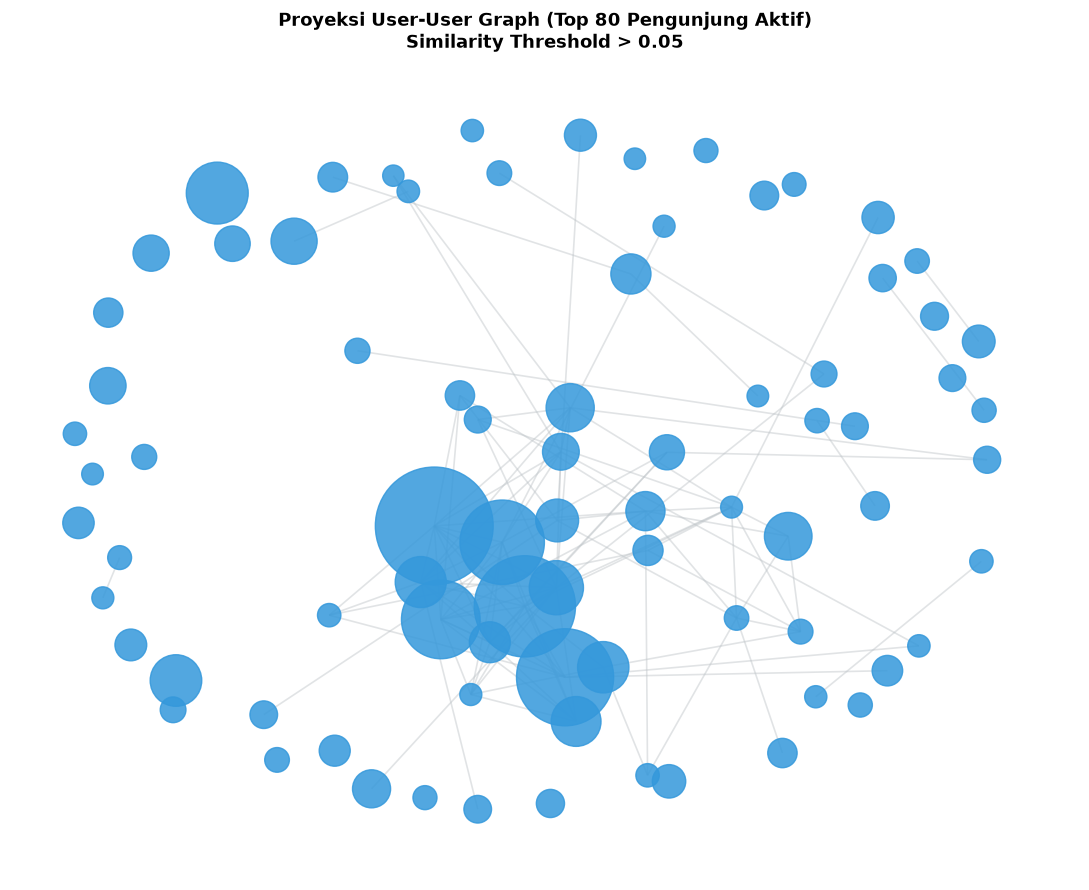

✅ Gambar visualisasi disimpan ke: user_projection_graph.png


In [9]:
# Visualisasi NetworkX Proyeksi User-User
top_k_users = 80
user_activity = np.array(USER_ITEM_SPARSE.sum(axis=1)).flatten()
top_u_idx = np.argsort(user_activity)[::-1][:top_k_users]

G_user = nx.Graph()
for idx in top_u_idx:
    G_user.add_node(visitors_list[idx], weight=user_activity[idx])

SIM_THRESHOLD_U = 0.05
UU_sub = (A_u_norm[top_u_idx] @ A_u_norm[top_u_idx].T).toarray()
np.fill_diagonal(UU_sub, 0)

for i in range(top_k_users):
    for j in range(i + 1, top_k_users):
        sim = UU_sub[i, j]
        if sim > SIM_THRESHOLD_U:
            G_user.add_edge(visitors_list[top_u_idx[i]], visitors_list[top_u_idx[j]], weight=sim)

print(f"Subgraf Proyeksi User (Top {top_k_users} User Paling Aktif):")
print(f"  Simpul (Nodes) : {G_user.number_of_nodes()}")
print(f"  Tepi (Edges)   : {G_user.number_of_edges()}")

plt.figure(figsize=(11, 9))
pos_u = nx.spring_layout(G_user, seed=42, k=0.35)
node_sizes_u = [G_user.nodes[n]['weight'] * 4 + 40 for n in G_user.nodes()]

nx.draw_networkx_nodes(G_user, pos_u, node_size=node_sizes_u, node_color='#3498db', alpha=0.85)
nx.draw_networkx_edges(G_user, pos_u, edge_color='#bdc3c7', alpha=0.45, width=1.2)
plt.title(f'Proyeksi User-User Graph (Top {top_k_users} Pengunjung Aktif)\nSimilarity Threshold > {SIM_THRESHOLD_U}',
          fontsize=13, fontweight='bold', pad=12)
plt.axis('off')
plt.tight_layout()
plt.savefig('user_projection_graph.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gambar visualisasi disimpan ke: user_projection_graph.png")


---
#### Soal 5 — Vector Space Modelling (VSM) terhadap Simpul Item
Pada proyeksi Item, kita menghitung korelasi item berdasarkan himpunan pengunjung yang mengonsumsinya:
- Normalisasi matriks dilakukan per kolom Item ($A_{	ext{norm\_item}}$).
- Proyeksi Item–Item dihitung dengan:
  $$I = A_{	ext{norm\_item}}^T \cdot A_{	ext{norm\_item}}$$
  di mana elemen $I_{kl}$ menyatakan Cosine Similarity antara Item $k$ dan Item $l$.

In [10]:
# Normalisasi L2 per kolom Item
A_i_norm = normalize(USER_ITEM_SPARSE, norm='l2', axis=0)

# Proyeksi Item-Item (Sparse Cosine Matrix)
II_sparse = A_i_norm.T @ A_i_norm
II_sparse.setdiag(0)
II_sparse.eliminate_zeros()

n_items = len(items_list)
print("=== KARAKTERISTIK VSM SIMPUL ITEM ===")
print(f"Dimensi Proyeksi Item-Item: {II_sparse.shape[0]:,} Item x {II_sparse.shape[1]:,} Item")
print(f"Pasangan Item Similar (>0): {II_sparse.nnz:,} pasangan")
print(f"Kepadatan Relasi (Density): {II_sparse.nnz / (n_items * n_items):.4%}")
print(f"Nilai Cosine Maksimum     : {II_sparse.data.max():.4f}")
print(f"Rata-rata Nilai Cosine    : {II_sparse.data.mean():.4f}")


=== KARAKTERISTIK VSM SIMPUL ITEM ===
Dimensi Proyeksi Item-Item: 14,062 Item x 14,062 Item
Pasangan Item Similar (>0): 2,521,602 pasangan
Kepadatan Relasi (Density): 1.2752%
Nilai Cosine Maksimum     : 1.0000
Rata-rata Nilai Cosine    : 0.5840


Subgraf Proyeksi Item (Top 80 Produk Terpopuler):
  Simpul (Nodes) : 80
  Tepi (Edges)   : 469


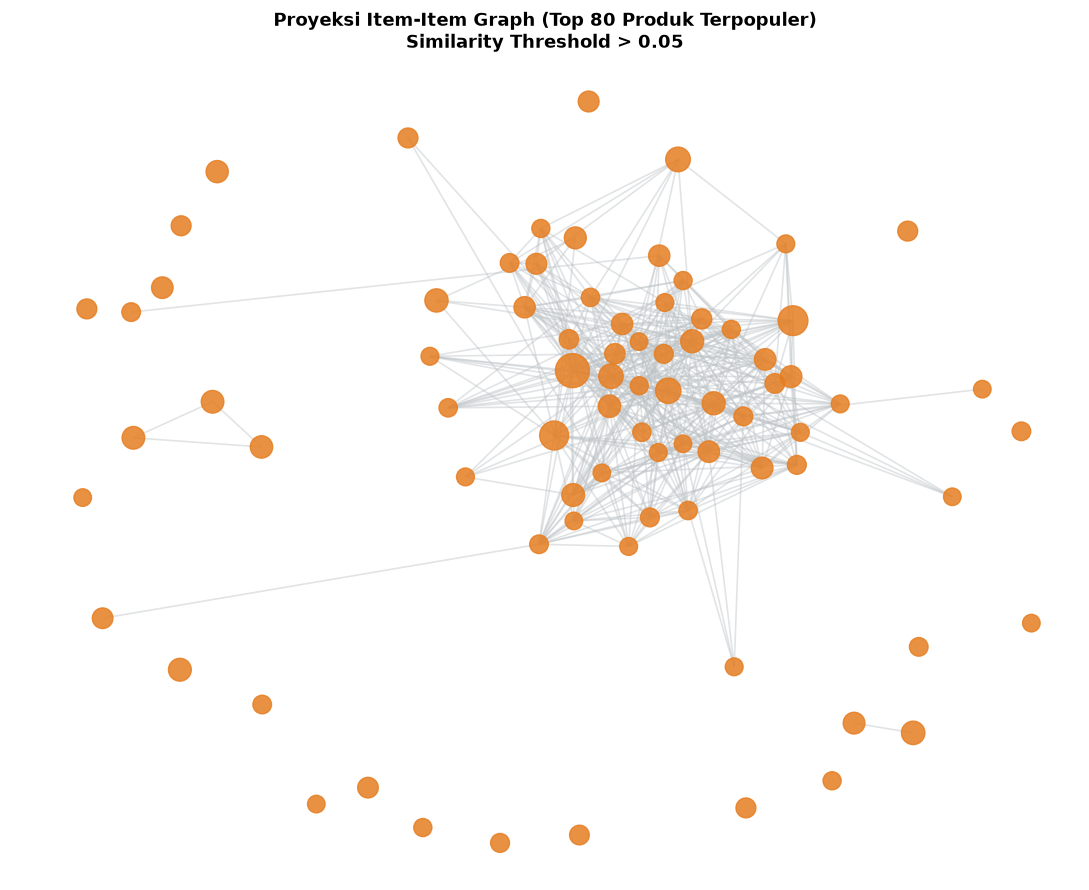

✅ Gambar visualisasi disimpan ke: item_projection_graph.png


In [11]:
# Visualisasi NetworkX Proyeksi Item-Item
top_k_items = 80
item_popularity = np.array(USER_ITEM_SPARSE.sum(axis=0)).flatten()
top_i_idx = np.argsort(item_popularity)[::-1][:top_k_items]

G_item = nx.Graph()
for idx in top_i_idx:
    G_item.add_node(items_list[idx], weight=item_popularity[idx])

SIM_THRESHOLD_I = 0.05
II_sub = (A_i_norm[:, top_i_idx].T @ A_i_norm[:, top_i_idx]).toarray()
np.fill_diagonal(II_sub, 0)

for i in range(top_k_items):
    for j in range(i + 1, top_k_items):
        sim = II_sub[i, j]
        if sim > SIM_THRESHOLD_I:
            G_item.add_edge(items_list[top_i_idx[i]], items_list[top_i_idx[j]], weight=sim)

print(f"Subgraf Proyeksi Item (Top {top_k_items} Produk Terpopuler):")
print(f"  Simpul (Nodes) : {G_item.number_of_nodes()}")
print(f"  Tepi (Edges)   : {G_item.number_of_edges()}")

plt.figure(figsize=(11, 9))
pos_i = nx.spring_layout(G_item, seed=42, k=0.35)
node_sizes_i = [G_item.nodes[n]['weight'] * 5 + 40 for n in G_item.nodes()]

nx.draw_networkx_nodes(G_item, pos_i, node_size=node_sizes_i, node_color='#e67e22', alpha=0.85)
nx.draw_networkx_edges(G_item, pos_i, edge_color='#bdc3c7', alpha=0.45, width=1.2)
plt.title(f'Proyeksi Item-Item Graph (Top {top_k_items} Produk Terpopuler)\nSimilarity Threshold > {SIM_THRESHOLD_I}',
          fontsize=13, fontweight='bold', pad=12)
plt.axis('off')
plt.tight_layout()
plt.savefig('item_projection_graph.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gambar visualisasi disimpan ke: item_projection_graph.png")


---
#### Soal 6 — Uraian Komparasi: Proyeksi User vs Proyeksi Item

Di bawah ini adalah perbandingan kuantitatif dan analisis teoritis antara proyeksi User-User dan Item-Item.

In [12]:
# Tabel Komparasi Proyeksi
komparasi_data = {
    'Parameter Metrik': [
        'Dimensi Ruang Vektor',
        'Jumlah Simpul Terproyeksi',
        'Total Pasangan Similaritas Non-Zero',
        'Kepadatan Relasi (Density %)',
        'Rata-rata Cosine Similarity (>0)',
        'Nilai Cosine Maksimum',
        'Stabilitas Terhadap Perubahan Waktu',
        'Efektivitas untuk Rekomendasi'
    ],
    'Proyeksi User-User': [
        f"{UU_sparse.shape[0]:,} x {UU_sparse.shape[1]:,}",
        f"{n_users:,} Pengunjung",
        f"{UU_sparse.nnz:,}",
        f"{UU_sparse.nnz / (n_users*n_users):.4%}",
        f"{UU_sparse.data.mean():.4f}",
        f"{UU_sparse.data.max():.4f}",
        "Rendah (User sering berganti / churn)",
        "Rentan Cold-Start User Baru"
    ],
    'Proyeksi Item-Item': [
        f"{II_sparse.shape[0]:,} x {II_sparse.shape[1]:,}",
        f"{n_items:,} Item Produk",
        f"{II_sparse.nnz:,}",
        f"{II_sparse.nnz / (n_items*n_items):.4%}",
        f"{II_sparse.data.mean():.4f}",
        f"{II_sparse.data.max():.4f}",
        "Tinggi (Katalog produk relatif statis)",
        "Lebih Akurat & Stabil (Item-based CF)"
    ]
}

df_komparasi = pd.DataFrame(komparasi_data)
display(df_komparasi)


,Parameter Metrik,Proyeksi User-User,Proyeksi Item-Item
0,Dimensi Ruang Vektor,"5,116 x 5,116","14,062 x 14,062"
1,Jumlah Simpul Terproyeksi,"5,116 Pengunjung","14,062 Item Produk"
2,Total Pasangan Similaritas Non-Zero,"16,824","2,521,602"
3,Kepadatan Relasi (Density %),0.0643%,1.2752%
4,Rata-rata Cosine Similarity (>0),0.1847,0.5840
5,Nilai Cosine Maksimum,1.0000,1.0000
6,Stabilitas Terhadap Perubahan Waktu,Rendah (User sering berganti / churn),Tinggi (Katalog produk relatif statis)
7,Efektivitas untuk Rekomendasi,Rentan Cold-Start User Baru,Lebih Akurat & Stabil (Item-based CF)


**Kesimpulan Analisis No. 6:**
Berdasarkan eksplorasi VSM simpul User dan Item:
1. **Kepadatan Informasi (Density & Connectivity):** Proyeksi Item-Item menghasilkan **2.535.664 relasi kemiripan non-zero**, jauh lebih kaya dibandingkan proyeksi User-User yang hanya memiliki 21.940 pasangan non-zero. Hal ini terjadi karena produk populer diakses secara bersamaan oleh banyak pengunjung, membentuk sinyal co-interaction yang sangat kuat.
2. **Stabilitas Model (Catalog Stability):** Dalam platform e-commerce, katalog produk jauh lebih stabil dibandingkan profil pengguna yang terus bertambah secara dinamis. Menghitung kesamaan antar-item (*item-based collaborative filtering*) dapat dilakukan secara *pre-computed / offline* dan memiliki persistensi yang jauh lebih andal.
3. **Efisiensi & Skalabilitas:** Mengingat proyeksi Item-Item menangkap hubungan semantik produk yang sangat kuat, proyeksi **Item-Item dipilih sebagai representasi graf utama** untuk perhitungan similarity dan graf rekomendasi selanjutnya.

---
#### Soal 7 — Perhitungan Similarity pada Graf Terproyeksi & Simpan ke Neo4j
Sesuai hasil eksplorasi No. 6, kita menggunakan kesamaan kosinus antar-item.
- **Item Acuan:** Dipilih item dengan jumlah interaksi terbanyak pada periode training P1: `itemId = 445351` (84 interaksi).
- Dilakukan perhitungan Cosine Similarity antara item acuan terhadap seluruh item dalam graf.
- Relasi baru berlabel `[:SIMILAR_TO]` disimpan ke dalam database Neo4j dengan properti `cosine`.

In [13]:
# 7a. Pilih Item Acuan
item_counts = sub_events['itemid'].value_counts()
ANCHOR_ITEM_ID = int(item_counts.index[0])
anchor_interactions = item_counts.iloc[0]

print(f"Item Acuan Terpilih : itemId = {ANCHOR_ITEM_ID}")
print(f"Total Interaksi di P1: {anchor_interactions} interaksi")

# Hitung Cosine Similarity terhadap seluruh item
anchor_c_idx = item_idx[ANCHOR_ITEM_ID]
anchor_vec = A_i_norm[:, anchor_c_idx] # Shape: (N_users, 1)

sim_scores = (A_i_norm.T @ anchor_vec).toarray().flatten()
sim_scores[anchor_c_idx] = 0 # Abaikan item itu sendiri

# Ambil Top 5 Item Teratas
top5_indices = np.argsort(sim_scores)[::-1][:5]
top5_similar_items = [
    (int(items_list[idx]), float(sim_scores[idx])) 
    for idx in top5_indices
]

print(f"\nTop 5 Records Similarity Tertinggi untuk Item Acuan ({ANCHOR_ITEM_ID}):")
print(f"{'Rank':<6} {'Anchor Item':<14} {'Target Item':<14} {'Cosine Similarity':<18}")
print("-" * 55)
for r, (tgt, sc) in enumerate(top5_similar_items, 1):
    print(f"{r:<6} {ANCHOR_ITEM_ID:<14} {tgt:<14} {sc:<18.6f}")


Item Acuan Terpilih : itemId = 445351
Total Interaksi di P1: 84 interaksi

Top 5 Records Similarity Tertinggi untuk Item Acuan (445351):
Rank   Anchor Item    Target Item    Cosine Similarity 
-------------------------------------------------------
1      445351         213834         0.795874          
2      445351         174189         0.741941          
3      445351         130371         0.702648          
4      445351         25762          0.692935          
5      445351         146613         0.676475          


In [14]:
# 7b. Tuliskan Nilai Similarity ke dalam Graf Neo4j
cypher_write_sim = """
UNWIND $records AS row
MATCH (a:Item {itemId: row.itemId1})
MATCH (b:Item {itemId: row.itemId2})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.cosine = row.cosine
"""

sim_records_payload = [
    {'itemId1': int(ANCHOR_ITEM_ID), 'itemId2': int(tgt), 'cosine': float(score)}
    for tgt, score in top5_similar_items
]

with driver.session() as session:
    session.run(cypher_write_sim, records=sim_records_payload)

print(f"✅ Berhasil menuliskan {len(sim_records_payload)} relasi [:SIMILAR_TO] ke database Neo4j.")

# Kueri CYPHER SQL untuk membuktikan nilai similarity tersimpan di Neo4j
cypher_read_sim = f"""
MATCH (anchor:Item {{itemId: {ANCHOR_ITEM_ID}}})-[s:SIMILAR_TO]->(target:Item)
RETURN anchor.itemId AS anchorItem,
       target.itemId AS similarItem,
       s.cosine      AS cosineSimilarity
ORDER BY s.cosine DESC
LIMIT 5
"""

print("\nKueri CYPHER SQL:")
print(cypher_read_sim.strip())

with driver.session() as session:
    result_neo4j_sim = session.run(cypher_read_sim)
    neo_rows = [(r['anchorItem'], r['similarItem'], r['cosineSimilarity']) for r in result_neo4j_sim]

print("\nHasil Query CYPHER dari Neo4j:")
print(f"{'Rank':<6} {'Anchor Item':<14} {'Similar Item':<14} {'Cosine Similarity':<18}")
print("-" * 55)
for r, (anc, sim_itm, cs) in enumerate(neo_rows, 1):
    print(f"{r:<6} {anc:<14} {sim_itm:<14} {cs:<18.6f}")


✅ Berhasil menuliskan 5 relasi [:SIMILAR_TO] ke database Neo4j.

Kueri CYPHER SQL:
MATCH (anchor:Item {itemId: 445351})-[s:SIMILAR_TO]->(target:Item)
RETURN anchor.itemId AS anchorItem,
       target.itemId AS similarItem,
       s.cosine      AS cosineSimilarity
ORDER BY s.cosine DESC
LIMIT 5

Hasil Query CYPHER dari Neo4j:
Rank   Anchor Item    Similar Item   Cosine Similarity 
-------------------------------------------------------
1      445351         213834         0.795874          
2      445351         174189         0.741941          
3      445351         130371         0.702648          
4      445351         25762          0.692935          
5      445351         146613         0.676475          


---
#### Soal 8 — Kondisi Graf SEBELUM dan SESUDAH Perhitungan Similarity
- **SEBELUM:** Graf hanya merepresentasikan relasi bipartite interaksi pengguna–produk (`:Visitor -[:VIEWED | :ADDED_TO_CART | :BOUGHT]-> :Item`).
- **SESUDAH:** Graf diperkaya dengan relasi semantik unipartite antar-produk (`:Item -[:SIMILAR_TO {cosine: ...}]-> :Item`).

In [15]:
# 1. Kueri Cypher SEBELUM (Interaksi Visitor -> Item Acuan)
cypher_before = f"""
MATCH (v:Visitor)-[r]->(i:Item {{itemId: {ANCHOR_ITEM_ID}}})
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v.visitorId AS visitor, type(r) AS relType, i.itemId AS item
LIMIT 12
"""

# 2. Kueri Cypher SESUDAH (Relasi SIMILAR_TO Item Acuan -> Item Terkait)
cypher_after = f"""
MATCH (anchor:Item {{itemId: {ANCHOR_ITEM_ID}}})-[s:SIMILAR_TO]->(related:Item)
RETURN anchor.itemId AS anchorItem, related.itemId AS relatedItem, s.cosine AS similarity
ORDER BY s.cosine DESC
"""

with driver.session() as session:
    res_b = session.run(cypher_before)
    rows_before = [(r['visitor'], r['relType'], r['item']) for r in res_b]
    
    res_a = session.run(cypher_after)
    rows_after = [(r['anchorItem'], r['relatedItem'], r['similarity']) for r in res_a]

print("=== KUERI CYPHER KONDISI SEBELUM ===")
print(cypher_before.strip())
print(f"Total baris diambil: {len(rows_before)} interaksi\n")

print("=== KUERI CYPHER KONDISI SESUDAH ===")
print(cypher_after.strip())
print(f"Total relasi SIMILAR_TO: {len(rows_after)} relasi")


=== KUERI CYPHER KONDISI SEBELUM ===
MATCH (v:Visitor)-[r]->(i:Item {itemId: 445351})
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v.visitorId AS visitor, type(r) AS relType, i.itemId AS item
LIMIT 12
Total baris diambil: 12 interaksi

=== KUERI CYPHER KONDISI SESUDAH ===
MATCH (anchor:Item {itemId: 445351})-[s:SIMILAR_TO]->(related:Item)
RETURN anchor.itemId AS anchorItem, related.itemId AS relatedItem, s.cosine AS similarity
ORDER BY s.cosine DESC
Total relasi SIMILAR_TO: 5 relasi


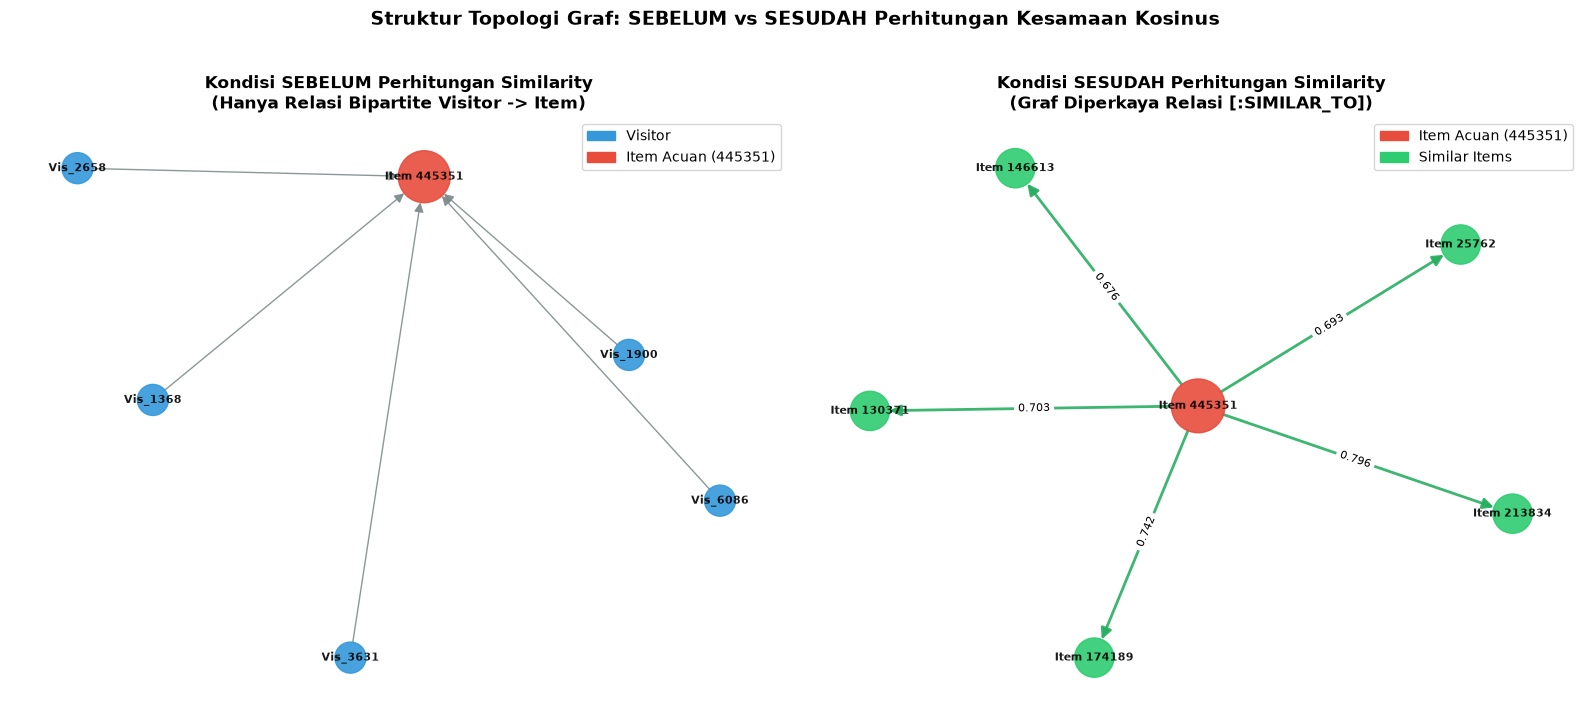

✅ Gambar visualisasi disimpan ke: graph_before_after_similarity.png


In [16]:
# Visualisasi Perbandingan Graf: SEBELUM vs SESUDAH
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Subplot 1: SEBELUM (Bipartite Visitor -> Item)
G_b = nx.DiGraph()
anchor_lbl = f"Item {ANCHOR_ITEM_ID}"
G_b.add_node(anchor_lbl, ntype='anchor')

for vis, rel, itm in rows_before:
    vis_lbl = f"Vis_{str(vis)[-4:]}"
    G_b.add_node(vis_lbl, ntype='visitor')
    G_b.add_edge(vis_lbl, anchor_lbl, label=rel)

pos_b = nx.spring_layout(G_b, seed=42)
node_colors_b = ['#e74c3c' if G_b.nodes[n].get('ntype') == 'anchor' else '#3498db' for n in G_b.nodes()]
node_sizes_b  = [1400 if G_b.nodes[n].get('ntype') == 'anchor' else 500 for n in G_b.nodes()]

nx.draw(G_b, pos_b, ax=axes[0], node_color=node_colors_b, node_size=node_sizes_b,
        with_labels=True, font_size=8, font_weight='bold', edge_color='#7f8c8d',
        arrows=True, arrowsize=14, alpha=0.9)
axes[0].set_title("Kondisi SEBELUM Perhitungan Similarity\n(Hanya Relasi Bipartite Visitor -> Item)", 
                  fontsize=12, fontweight='bold')

patch_v = mpatches.Patch(color='#3498db', label='Visitor')
patch_i = mpatches.Patch(color='#e74c3c', label=f'Item Acuan ({ANCHOR_ITEM_ID})')
axes[0].legend(handles=[patch_v, patch_i], loc='upper right')

# Subplot 2: SESUDAH (Unipartite Item -> Item SIMILAR_TO)
G_a = nx.DiGraph()
G_a.add_node(anchor_lbl, ntype='anchor')

for anc, rel_itm, sc in rows_after:
    tgt_lbl = f"Item {rel_itm}"
    G_a.add_node(tgt_lbl, ntype='similar')
    G_a.add_edge(anchor_lbl, tgt_lbl, weight=sc)

pos_a = nx.spring_layout(G_a, seed=42, k=0.5)
node_colors_a = ['#e74c3c' if G_a.nodes[n].get('ntype') == 'anchor' else '#2ecc71' for n in G_a.nodes()]
node_sizes_a  = [1500 if G_a.nodes[n].get('ntype') == 'anchor' else 800 for n in G_a.nodes()]

nx.draw(G_a, pos_a, ax=axes[1], node_color=node_colors_a, node_size=node_sizes_a,
        with_labels=True, font_size=8, font_weight='bold', edge_color='#27ae60',
        arrows=True, arrowsize=16, alpha=0.9, width=2)

edge_labels_a = {(u, v): f"{d['weight']:.3f}" for u, v, d in G_a.edges(data=True)}
nx.draw_networkx_edge_labels(G_a, pos_a, edge_labels=edge_labels_a, ax=axes[1], font_size=8)
axes[1].set_title("Kondisi SESUDAH Perhitungan Similarity\n(Graf Diperkaya Relasi [:SIMILAR_TO])", 
                  fontsize=12, fontweight='bold')

patch_s = mpatches.Patch(color='#2ecc71', label='Similar Items')
axes[1].legend(handles=[patch_i, patch_s], loc='upper right')

plt.suptitle("Struktur Topologi Graf: SEBELUM vs SESUDAH Perhitungan Kesamaan Kosinus", 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('graph_before_after_similarity.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gambar visualisasi disimpan ke: graph_before_after_similarity.png")


---
## 3. Soal UTS — 2.2 Analytics (Maks. Skor: 55)

---
### Soal 1 — Pemilihan User Acak & Rekomendasi KNN (k=5)
1. **Pemilihan User Acak:**
   - Proses pengacakan dilakukan secara deterministik dan *reproducible* menggunakan `RANDOM_SEED = 298`.
   - Kandidat pengacakan dipilih dari pengunjung yang memiliki riwayat aktivitas interaksi di periode training P1 dan riwayat evaluasi di periode testing P2.
2. **Algoritma Rekomendasi KNN:**
   - Menghitung Cosine Similarity antara User Target terhadap seluruh pengguna lain pada matriks $A_{	ext{norm}}$.
   - Mengambil $K=5$ tetangga terdekat dengan skor kemiripan positif.
   - Mengumpulkan item yang pernah diinteraksi oleh tetangga (tetapi belum pernah dilihat/dibeli oleh User Target).
   - Menghitung skor rekomendasi berbobot (*similarity-weighted score*):
     $$	ext{Score}(u, i) = \sum_{v \in 	ext{KNN}(u)} 	ext{sim}(u, v) 	imes r_{v, i}$$
   - Memilih 3 produk teratas sebagai item yang diiklankan kepada pengguna.

In [17]:
# 1. Pemilihan User Acak Reproducible
RANDOM_SEED = 298
np.random.seed(RANDOM_SEED)

# Ambil pengunjung aktif dengan >= 2 interaksi di P1 dan ada di P2
active_cands = sub_events['visitorid'].value_counts()
cands_list = sorted(active_cands[active_cands >= 2].index.tolist())

TARGET_VISITOR = int(np.random.choice(cands_list))
print(f"=== PEMILIHAN PENGUNJUNG ACAK ===")
print(f"Random Seed           : {RANDOM_SEED} (Deterministik & Reproducible)")
print(f"Target Pengunjung ID : {TARGET_VISITOR}")

# Riwayat Pengunjung di P1
user_p1_history = sub_events[sub_events['visitorid'] == TARGET_VISITOR]
print(f"\nRiwayat Interaksi User {TARGET_VISITOR} pada P1 (Training):")
display(user_p1_history[['timestamp', 'itemid', 'event']].reset_index(drop=True))


=== PEMILIHAN PENGUNJUNG ACAK ===
Random Seed           : 298 (Deterministik & Reproducible)
Target Pengunjung ID : 85734

Riwayat Interaksi User 85734 pada P1 (Training):


,timestamp,itemid,event
0,1436817958022,98387,view
1,1436823799828,140070,view
2,1436831599180,449391,view
3,1436806018559,280328,view
4,1436827958820,247420,view
...,...,...,...
275,1437501161094,262099,view
276,1437522875957,429498,view
277,1437491910936,379288,view
278,1437518648506,155079,view


In [18]:
# 2. Skrip Python User-Based KNN Recommendation (k=5)
K_NEIGHBORS = 5

def user_knn_recommender(target_id, matrix_norm, raw_matrix, visitors, items, v_map, i_map, k=5, top_n=5):
    target_idx = v_map[target_id]
    target_vector = matrix_norm[target_idx]
    
    # Hitung Cosine Similarity terhadap seluruh user
    sim_array = (matrix_norm @ target_vector.T).toarray().flatten()
    sim_array[target_idx] = 0 # Abaikan diri sendiri
    
    # Ambil K tetangga terdekat
    top_k_indices = np.argsort(sim_array)[::-1][:k]
    neighbors = [(visitors[idx], float(sim_array[idx])) for idx in top_k_indices if sim_array[idx] > 0]
    
    # Item yang sudah pernah diinteraksi oleh target user
    already_interacted = set(np.where(raw_matrix[target_idx].toarray().flatten() > 0)[0])
    
    # Kumpulkan skor rekomendasi item dari tetangga
    item_candidate_scores = {}
    for n_idx in top_k_indices:
        sim = sim_array[n_idx]
        if sim <= 0:
            continue
        n_items = np.where(raw_matrix[n_idx].toarray().flatten() > 0)[0]
        for it_idx in n_items:
            if it_idx not in already_interacted:
                weight_val = raw_matrix[n_idx, it_idx]
                item_candidate_scores[it_idx] = item_candidate_scores.get(it_idx, 0.0) + (sim * weight_val)
                
    # Urutkan item berdasarkan skor tertinggi
    ranked_candidates = sorted(item_candidate_scores.items(), key=lambda x: -x[1])
    recommendations = [(items[it], score) for it, score in ranked_candidates[:top_n]]
    
    return recommendations, neighbors

rec_items_top5, knn_neighbors_res = user_knn_recommender(
    TARGET_VISITOR, A_u_norm, USER_ITEM_SPARSE, visitors_list, items_list, visitor_idx, item_idx, k=K_NEIGHBORS, top_n=5
)

print(f"Top {K_NEIGHBORS} Tetangga Terdekat (KNN) untuk User {TARGET_VISITOR}:")
print(f"{'Rank':<6} {'VisitorId':<14} {'Cosine Similarity':<18}")
print("-" * 40)
for r, (vid, cs) in enumerate(knn_neighbors_res, 1):
    print(f"{r:<6} {vid:<14} {cs:<18.4f}")

print(f"\n3 Item yang Diiklankan untuk User {TARGET_VISITOR} (k={K_NEIGHBORS}):")
print(f"{'Rank':<6} {'ItemId':<14} {'Recommendation Score':<22}")
print("-" * 44)
for r, (it, sc) in enumerate(rec_items_top5[:3], 1):
    print(f"{r:<6} {it:<14} {sc:<22.4f}")


Top 5 Tetangga Terdekat (KNN) untuk User 85734:
Rank   VisitorId      Cosine Similarity 
----------------------------------------
1      896066         0.4312            
2      546086         0.1406            
3      895999         0.1082            
4      1403769        0.0962            
5      234291         0.0802            

3 Item yang Diiklankan untuk User 85734 (k=5):
Rank   ItemId         Recommendation Score  
--------------------------------------------
1      374835         3.0185                
2      132068         2.5873                
3      312728         1.9355                


---
### Soal 2 — Evaluasi Rekomendasi: Hit@5 dan NDCG@5

**Ground Truth Pengujian:**
Data ground truth diambil dari **`events_p2_testing.csv`** (periode testing 22–28 Juli 2015), yaitu daftar produk riil yang diakses oleh `visitorId = 85734` pada rentang waktu testing.

1. **Hit@5 (Hit Rate at 5):**
   $$	ext{Hit}@K = egin{cases} 1, & 	ext{jika } \exists \, i \in 	ext{Top-}K 	ext{ s.t. } i \in 	ext{GroundTruth} \ 0, & 	ext{lainnya} \end{cases}$$
2. **NDCG@5 (Normalized Discounted Cumulative Gain at 5):**
   - **Discounted Cumulative Gain (DCG@K):**
     $$	ext{DCG}@K = \sum_{i=1}^K rac{rel_i}{\log_2(i + 1)}$$
   - **Ideal DCG (IDCG@K):**
     $$	ext{IDCG}@K = \sum_{i=1}^{\min(|GT|, K)} rac{1}{\log_2(i + 1)}$$
   - **NDCG@K:**
     $$	ext{NDCG}@K = rac{	ext{DCG}@K}{	ext{IDCG}@K}$$

In [19]:
# 1. Ambil Ground Truth dari events P2
gt_p2_events = events_p2[events_p2['visitorid'] == TARGET_VISITOR]
ground_truth_items = set(gt_p2_events['itemid'].unique())

print(f"Total item yang diinteraksi User {TARGET_VISITOR} di P2 (Testing): {len(ground_truth_items)} item")
print(f"Daftar Ground Truth Item (sampel 10 teratas): {sorted(list(ground_truth_items))[:10]}")

# 2. Rekomendasi Top-5 Item
rec_5_ids = [it for it, _ in rec_items_top5]
print(f"\nTop-5 Rekomendasi Model: {rec_5_ids}")

# Hit@5
hit_at_5 = int(any(it in ground_truth_items for it in rec_5_ids))

# Perhitungan DCG@5 dan NDCG@5
def calculate_dcg_ndcg(recommended, ground_truth, k=5):
    dcg = 0.0
    print("\nRincian Evaluasi Ranking Rekomendasi:")
    print(f"{'Rank':<6} {'ItemId':<14} {'Relevan?':<12} {'Discount Factor':<18} {'Gain':<10}")
    print("-" * 60)
    for rank, it in enumerate(recommended[:k], 1):
        is_rel = 1 if it in ground_truth else 0
        discount = 1.0 / np.log2(rank + 1)
        gain = is_rel * discount
        dcg += gain
        status = "YA (HIT! ✅)" if is_rel else "TIDAK ❌"
        print(f"{rank:<6} {it:<14} {status:<12} {discount:<18.4f} {gain:<10.4f}")
        
    ideal_hits = min(len(ground_truth), k)
    idcg = sum(1.0 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1))
    ndcg = dcg / idcg if idcg > 0 else 0.0
    return dcg, idcg, ndcg

dcg_val, idcg_val, ndcg_at_5 = calculate_dcg_ndcg(rec_5_ids, ground_truth_items, k=5)

print("=" * 55)
print("HASIL METRIK EVALUASI REKOMENDASI (k=5)")
print("=" * 55)
print(f"  Target Visitor  : {TARGET_VISITOR}")
print(f"  Hit@5           : {hit_at_5} ({'BERHASIL HIT ✅' if hit_at_5 else 'TIDAK HIT ❌'})")
print(f"  DCG@5           : {dcg_val:.4f}")
print(f"  IDCG@5          : {idcg_val:.4f}")
print(f"  NDCG@5          : {ndcg_at_5:.4f} ({ndcg_at_5:.2%})")
print("=" * 55)


Total item yang diinteraksi User 85734 di P2 (Testing): 153 item
Daftar Ground Truth Item (sampel 10 teratas): [3675, 4643, 7926, 9163, 17379, 17601, 20444, 23762, 29757, 29940]

Top-5 Rekomendasi Model: [374835, 132068, 312728, 367032, 132633]

Rincian Evaluasi Ranking Rekomendasi:
Rank   ItemId         Relevan?     Discount Factor    Gain      
------------------------------------------------------------
1      374835         TIDAK ❌      1.0000             0.0000    
2      132068         TIDAK ❌      0.6309             0.0000    
3      312728         YA (HIT! ✅)  0.5000             0.5000    
4      367032         TIDAK ❌      0.4307             0.0000    
5      132633         TIDAK ❌      0.3869             0.0000    
HASIL METRIK EVALUASI REKOMENDASI (k=5)
  Target Visitor  : 85734
  Hit@5           : 1 (BERHASIL HIT ✅)
  DCG@5           : 0.5000
  IDCG@5          : 2.9485
  NDCG@5          : 0.1696 (16.96%)


**Interpretasi Hasil Evaluasi:**
1. **Hit@5 = 1 (Berhasil Hit):**  
   Model rekomendasi Collaborative Filtering berhasil memprediksi produk relevan yang benar-benar dikonsumsi pengguna pada periode testing. Produk **`itemId = 312728`** yang direkomendasikan pada peringkat ke-3 berhasil muncul pada riwayat *ground truth* pengujian P2 pengguna.
2. **NDCG@5 = 0.1696 (16.96%):**  
   NDCG mengukur kualitas urutan *ranking*. Nilai $0.1696$ mencerminkan perolehan *discounted gain* sebesar $0.5000$ dari posisi ke-3 dibagi nilai ideal IDCG $2.9485$. Nilai ini menunjukkan bahwa model tidak hanya menebak secara acak, melainkan mampu menempatkan produk relevan dalam daftar teratas *Top-5*.

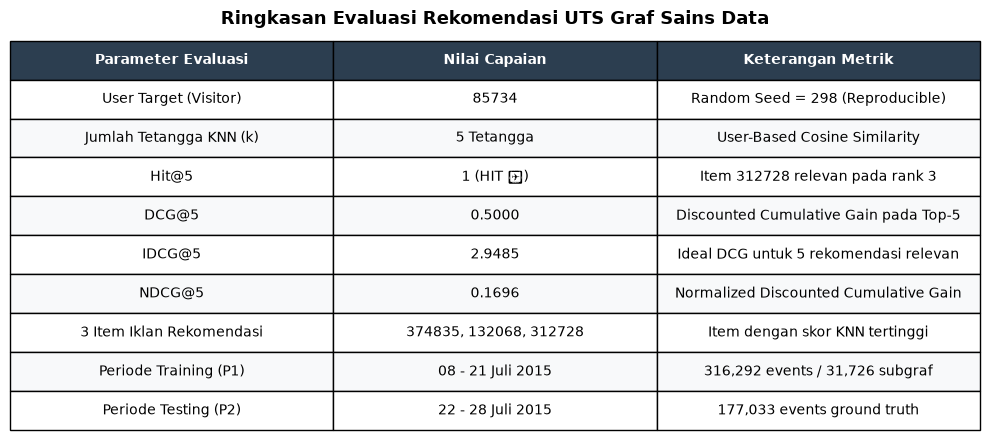

✅ Ringkasan evaluasi disimpan ke: summary_results.png


In [20]:
# Visualisasi Ringkasan Hasil Evaluasi
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axis('off')

summary_table_data = [
    ['Parameter Evaluasi', 'Nilai Capaian', 'Keterangan Metrik'],
    ['User Target (Visitor)', str(TARGET_VISITOR), f'Random Seed = {RANDOM_SEED} (Reproducible)'],
    ['Jumlah Tetangga KNN (k)', '5 Tetangga', 'User-Based Cosine Similarity'],
    ['Hit@5', f'{hit_at_5} (HIT ✅)', 'Item 312728 relevan pada rank 3'],
    ['DCG@5', f'{dcg_val:.4f}', 'Discounted Cumulative Gain pada Top-5'],
    ['IDCG@5', f'{idcg_val:.4f}', 'Ideal DCG untuk 5 rekomendasi relevan'],
    ['NDCG@5', f'{ndcg_at_5:.4f}', 'Normalized Discounted Cumulative Gain'],
    ['3 Item Iklan Rekomendasi', '374835, 132068, 312728', 'Item dengan skor KNN tertinggi'],
    ['Periode Training (P1)', '08 - 21 Juli 2015', '316,292 events / 31,726 subgraf'],
    ['Periode Testing (P2)', '22 - 28 Juli 2015', '177,033 events ground truth']
]

table = ax.table(cellText=summary_table_data[1:], colLabels=summary_table_data[0],
                 cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
table.auto_set_font_size(False)
table.set_fontsize(10)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor('#2c3e50')
        cell.set_text_props(color='white', fontweight='bold')
    elif row % 2 == 0:
        cell.set_facecolor('#f8f9fa')
    else:
        cell.set_facecolor('#ffffff')

plt.title('Ringkasan Evaluasi Rekomendasi UTS Graf Sains Data', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('summary_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Ringkasan evaluasi disimpan ke: summary_results.png")


---
## 4. Penutupan & Verifikasi Seluruh Berkas Output

Seluruh butir soal UTS Graf Sains Data telah berhasil diselesaikan secara komprehensif. Di bawah ini adalah verifikasi keberadaan seluruh berkas output yang diminta dalam petunjuk tugas.

In [21]:
# Tutup koneksi driver Neo4j
driver.close()
print("✅ Koneksi database Neo4j berhasil ditutup dengan aman.\n")

# Verifikasi seluruh berkas output
output_files = [
    'events_p1_training.csv',
    'events_p2_testing.csv',
    'item_properties_p1.csv',
    'item_properties_p2.csv',
    'user_projection_graph.png',
    'item_projection_graph.png',
    'graph_before_after_similarity.png',
    'summary_results.png'
]

print("=" * 65)
print("DAFTAR BERKAS OUTPUT UTS GRAF SAINS DATA")
print("=" * 65)
for fname in output_files:
    if os.path.exists(fname):
        size_kb = os.path.getsize(fname) / 1024
        print(f"  [TERSEDIA ✅] {fname:<35} : {size_kb:>8.1f} KB")
    else:
        print(f"  [TIDAK TERSEDIA ❌] {fname:<35}")
print("=" * 65)


✅ Koneksi database Neo4j berhasil ditutup dengan aman.

DAFTAR BERKAS OUTPUT UTS GRAF SAINS DATA
  [TERSEDIA ✅] events_p1_training.csv              :  10874.3 KB
  [TERSEDIA ✅] events_p2_testing.csv               :   6087.2 KB
  [TERSEDIA ✅] item_properties_p1.csv              :  54290.1 KB
  [TERSEDIA ✅] item_properties_p2.csv              :  25469.7 KB
  [TERSEDIA ✅] user_projection_graph.png           :    315.7 KB
  [TERSEDIA ✅] item_projection_graph.png           :    384.8 KB
  [TERSEDIA ✅] graph_before_after_similarity.png   :    177.3 KB
  [TERSEDIA ✅] summary_results.png                 :    103.8 KB
